# PathSnap · Team 111 — Feature engineering
**Deliverable: complete source code for the team's feature extraction and preparation.**

Input: the tables saved by `01_data_processing.ipynb` (points + candidates). **Run notebook 01 first**
(in Colab: in the same session).

| Step | What |
|---|---|
| 1 | Learning unit and target |
| 2 | Relative-distance features |
| 3 | Kinematics: heading and speed (with evidence for the window) |
| 4 | Direction feature |
| 5 | Geometry and network features |
| 6 | Temporal-context features (neighbouring GPS points) |
| 7 | Self-calibrating noise features (team 111) |
| 8 | Final feature matrix: 22 features, checks |
| 9 | Evidence: how informative is each feature? |
| 10 | Preparation for modelling: filtering, sampling, group-aware folds, saving |
| 11 | Consistency check with the production code used by the API |

Every feature uses **only the GPS track and the road network** — never the reference route — so the
identical computation runs at inference time.

## Step 0 — Setup and inputs

In [2]:
import os, time, zipfile, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")


def find_raw(start_dirs):
    for start in start_dirs:
        for d, subdirs, _ in os.walk(start):
            if "train" in subdirs and "student_test" in subdirs:
                return d
            if d.count(os.sep) - start.count(os.sep) > 3:
                subdirs[:] = []
    return None


IN_COLAB = os.path.isdir("/content")
if IN_COLAB:
    ROOT = "/content"
RAW = find_raw([d for d in [os.path.join(ROOT, "data", "raw"), ROOT] if os.path.isdir(d)])
if RAW is None and IN_COLAB:
    from google.colab import files
    print("Dataset not found -> choose Student_folder.zip")
    for name in files.upload():
        if name.endswith(".zip"):
            zipfile.ZipFile(name).extractall("/content/")
    RAW = find_raw(["/content"])
assert RAW is not None, "Dataset not found (train/ and student_test/ folders)"

DP = os.path.join(ROOT, "data", "processed", "dp")
OUT = os.path.join(ROOT, "data", "processed", "fe"); os.makedirs(OUT, exist_ok=True)
RES = os.path.join(ROOT, "results"); os.makedirs(RES, exist_ok=True)
PARTS = ["train", "student_test"]
R = 6371008.8
assert os.path.exists(os.path.join(DP, "train_candidates.pkl")), \
    f"Run 01_data_processing.ipynb first: its outputs are missing in {DP}"
points = {p: pd.read_pickle(os.path.join(DP, f"{p}_points.pkl")) for p in PARTS}
cands = {p: pd.read_pickle(os.path.join(DP, f"{p}_candidates.pkl")) for p in PARTS}
dp_summary = pd.read_csv(os.path.join(RES, "dp_processing_summary.csv"), dtype={"trip": str})
for p in PARTS:
    print(f"{p}: {len(points[p]):,} GPS points, {len(cands[p]):,} candidate rows")

ModuleNotFoundError: No module named 'numpy'

## Step 1 — Learning unit and target
One row = **(GPS observation, candidate arc)**. Target `y = 1` if the candidate is that observation's
reference arc (from the route alignment in notebook 01), else 0. A classifier then scores every candidate,
and the highest score per observation is the prediction.

In [ ]:
for p in PARTS:
    c = cands[p]
    per_pt = c.groupby(["trip", "pt"]).is_label.max()
    print(f"{p}: positive rate {c.is_label.mean():.3f} | observations with the true arc among candidates {per_pt.mean():.3f}")

train: positive rate 0.162 | observations with the true arc among candidates 0.888
student_test: positive rate 0.168 | observations with the true arc among candidates 0.996


**Class imbalance:** only ~16% of rows are positive (one true arc among ~6 candidates), so we evaluate with
macro F1 / log loss and observation-level Top-1 accuracy, not plain accuracy.

## Helper — reload the trip's road geometry in the same metric frame as notebook 01

In [ ]:
def trip_geometry(part, tid, pts):
    d = os.path.join(RAW, part, tid)
    nodes = np.loadtxt(os.path.join(d, f"{tid}.nodes"), ndmin=2)
    arcs = np.loadtxt(os.path.join(d, f"{tid}.arcs"), dtype=int, ndmin=2)
    lon0, lat0 = pts.lon.mean(), pts.lat.mean()          # same origin as notebook 01 (cleaned track mean)
    nxy = np.column_stack([np.radians(nodes[:, 0] - lon0) * R * np.cos(np.radians(lat0)),
                           np.radians(nodes[:, 1] - lat0) * R])
    A = nxy[arcs[:, 0]]; AB = nxy[arcs[:, 1]] - A
    return dict(arcs=arcs, A=A, AB=AB,
                bearing=(np.degrees(np.arctan2(AB[:, 0], AB[:, 1])) + 360) % 360,
                out_deg=np.bincount(arcs[:, 0], minlength=len(nodes)),
                in_deg=np.bincount(arcs[:, 1], minlength=len(nodes)))


def point_arc_dist(p, arc_ids, g):
    a, ab = g["A"][arc_ids], g["AB"][arc_ids]
    t = np.clip(((p - a) * ab).sum(1) / np.maximum((ab ** 2).sum(1), 1e-9), 0, 1)
    return np.hypot(*(p - (a + t[:, None] * ab)).T)


def angle_diff(a, b):
    return np.abs((a - b + 180.0) % 360.0 - 180.0)          # 0..180 degrees

## Steps 2–7 — Feature extraction, explained group by group
The function below computes every feature for one trip. Each block is one feature group:

**2. Relative distance** — raw distance alone can't tell if a candidate is *the closest*:
`dist_rank` (0 = nearest), `dist_minus_min` (gap to the nearest), `dist_ratio`, `n_cands` (road density).

**3. Kinematics** — `speed`, `move_dist` from a ±2-point window; `dt_prev` time since previous point.

**4. Direction** — `head_diff` = angle between GPS heading and arc direction. Separates the two directions
of a two-way road (identical distance!).

**5. Geometry / network** — `dist`, `arc_len`, `t_proj` (position on the arc), `end_dist` (distance to the
nearer arc end: near junctions the true arc is ambiguous), `has_reverse` (two-way), `out_deg_to`, `in_deg_from`.

**6. Temporal context** — does the *same arc* also explain the neighbours i−3…i+3? `ctx_dist_mean`,
`ctx_dist_max`, `ctx_head_diff`, `head_consistency` (share of neighbours heading within 45° of the arc).

**7. Self-calibrating noise model (team 111)** — each trip estimates its own GPS noise
`trip_sigma = 1.4826 × median(distance to the nearest arc)` (robust, MAD-style; GPS + map only) and distances
are also given in units of it: `dist_z`, `ctx_dist_z`. One model then works for clean and noisy trips.

In [ ]:
FEATURES = ["dist", "dist_rank", "dist_minus_min", "dist_ratio", "n_cands",
            "head_diff", "speed", "move_dist", "arc_len", "t_proj", "end_dist",
            "has_reverse", "ctx_dist_mean", "ctx_dist_max", "ctx_head_diff",
            "dt_prev", "out_deg_to", "in_deg_from",
            "trip_sigma", "dist_z", "ctx_dist_z", "head_consistency"]


def extract_features(part, tid, pts, c, win=2, ctx=3):
    pts = pts.sort_values("pt"); c = c.sort_values(["pt", "dist_m"]).reset_index(drop=True)
    g = trip_geometry(part, tid, pts)
    xy, t = pts[["x", "y"]].values, pts.t.values
    N = len(xy); pi = c.pt.values; arc = c.arc.values
    f = pd.DataFrame({"trip": tid, "pt": pi, "arc": arc, "y": c.is_label.astype(int).values})

    # --- 5. geometry / network (part 1)
    f["dist"] = c.dist_m.values
    f["arc_len"] = c.arc_len_m.values
    f["t_proj"] = c.t_proj.values
    f["end_dist"] = np.minimum(f.t_proj, 1 - f.t_proj) * f.arc_len
    f["has_reverse"] = c.two_way.astype(int).values

    # --- 2. relative distance
    grp = f.groupby("pt")["dist"]
    nearest = grp.transform("min")
    f["dist_rank"] = grp.rank(method="first").astype(int) - 1
    f["dist_minus_min"] = f.dist - nearest
    f["dist_ratio"] = f.dist / (nearest + 1.0)
    f["n_cands"] = grp.transform("size")

    # --- 3. kinematics (centred +-win window)
    i0 = np.clip(np.arange(N) - win, 0, N - 1); i1 = np.clip(np.arange(N) + win, 0, N - 1)
    dxy = xy[i1] - xy[i0]
    move = np.hypot(dxy[:, 0], dxy[:, 1])
    heading = (np.degrees(np.arctan2(dxy[:, 0], dxy[:, 1])) + 360) % 360
    speed = move / np.maximum(t[i1] - t[i0], 1e-6)
    f["speed"] = speed[pi]; f["move_dist"] = move[pi]
    f["dt_prev"] = np.concatenate([[1.0], np.diff(t)])[pi]

    # --- 4. direction
    f["head_diff"] = angle_diff(heading[pi], g["bearing"][arc])

    # --- 6. temporal context (neighbours i-ctx .. i+ctx against the same arc)
    cd, ch = [], []
    for o in range(-ctx, ctx + 1):
        j = np.clip(pi + o, 0, N - 1)
        cd.append(point_arc_dist(xy[j], arc, g))
        ch.append(angle_diff(heading[j], g["bearing"][arc]))
    cd, ch = np.vstack(cd), np.vstack(ch)
    f["ctx_dist_mean"] = cd.mean(0); f["ctx_dist_max"] = cd.max(0)
    f["ctx_head_diff"] = ch.mean(0); f["head_consistency"] = (ch < 45).mean(0)

    # --- 5. network (part 2)
    f["out_deg_to"] = g["out_deg"][g["arcs"][arc, 1]]
    f["in_deg_from"] = g["in_deg"][g["arcs"][arc, 0]]

    # --- 7. self-calibrating noise model
    sigma = float(np.clip(1.4826 * np.median(nearest.groupby(f.pt).first()), 2.0, 80.0))
    f["trip_sigma"] = sigma
    f["dist_z"] = f.dist / sigma
    f["ctx_dist_z"] = f.ctx_dist_mean / sigma
    return f


demo = extract_features("student_test", "00000076", points["student_test"].query("trip == '00000076'"),
                        cands["student_test"].query("trip == '00000076'"))
print(f"trip 76: {len(demo):,} rows x {len(FEATURES)} features")
demo[demo.pt == 743][["arc", "y", "dist", "dist_rank", "head_diff", "speed", "ctx_dist_mean", "head_consistency", "dist_z"]].round(2)

trip 76: 11,130 rows x 22 features


,arc,y,dist,dist_rank,head_diff,speed,ctx_dist_mean,head_consistency,dist_z
5828,26592,1,4.05,0,4.15,11.37,18.62,1.0,0.47
5829,26589,0,4.05,1,175.85,11.37,18.62,0.0,0.47
5830,1921,0,4.06,2,175.45,11.37,17.53,0.0,0.47
5831,26590,0,4.06,3,4.55,11.37,17.53,1.0,0.47
5832,26591,0,8.38,4,175.78,11.37,18.11,0.0,0.97
5833,12365,0,8.38,5,4.22,11.37,18.11,1.0,0.97
5834,1922,0,12.22,6,3.10,11.37,21.77,1.0,1.42
5835,1920,0,12.22,7,86.96,11.37,23.24,0.0,1.42


Above: one GPS point of trip 76. Several candidates are at the **same distance** (both directions of the same
road); `head_diff` (~4° vs ~176°) and the context features single out the true arc (`y = 1`).

### Run feature extraction on all 90 trips

In [ ]:
t0 = time.time()
feat = {}
for p in PARTS:
    feat[p] = pd.concat([extract_features(p, tid, points[p][points[p].trip == tid], cands[p][cands[p].trip == tid])
                         for tid in sorted(points[p].trip.unique())], ignore_index=True)
    feat[p]["partition"] = p
print(f"features for {sum(len(v) for v in feat.values()):,} rows in {time.time() - t0:.0f} s")

features for 1,253,608 rows in 7 s


### Evidence for Step 3: why a ±2-point heading window (not a single 1-s step)?
Heading error *on the true arc*, by speed band (train, reliable labels):

In [ ]:
rows = []
for tid in sorted(points["train"].trip.unique()):
    pts = points["train"][points["train"].trip == tid].sort_values("pt")
    if (pts.label_dist_m > 100).mean() > 0.3:
        continue
    g = trip_geometry("train", tid, pts); xy = pts[["x", "y"]].values; t = pts.t.values; N = len(xy)
    i0 = np.clip(np.arange(N) - 2, 0, N - 1); i1 = np.clip(np.arange(N) + 2, 0, N - 1)
    d2 = xy[i1] - xy[i0]; d1 = np.diff(xy, axis=0, prepend=xy[:1])
    h_win = (np.degrees(np.arctan2(d2[:, 0], d2[:, 1])) + 360) % 360
    h_1s = (np.degrees(np.arctan2(d1[:, 0], d1[:, 1])) + 360) % 360
    true_b = g["bearing"][pts.label_arc.values]
    rows.append(pd.DataFrame(dict(speed=np.hypot(*d2.T) / np.maximum(t[i1] - t[i0], 1e-6),
                                  wrong_1s=angle_diff(h_1s, true_b) > 90, wrong_win=angle_diff(h_win, true_b) > 90)))
hd = pd.concat(rows)
hd["speed_band"] = pd.cut(hd.speed, [-0.1, 1, 3, 8, 15, 100], labels=["<1 m/s", "1-3", "3-8", "8-15", ">15"])
(hd.groupby("speed_band", observed=True)[["wrong_1s", "wrong_win"]].mean() * 100).round(1).rename(
    columns={"wrong_1s": "% wrong direction, 1-s step", "wrong_win": "% wrong direction, ±2 window"})

,"% wrong direction, 1-s step","% wrong direction, ±2 window"
speed_band,,
<1 m/s,45.8,42.4
1-3,42.1,29.9
3-8,24.4,6.2
8-15,4.2,0.2
>15,0.3,0.1


At low speed GPS jitter dominates a 1-s step; the window helps, and the `speed` feature lets the model learn
when heading can't be trusted at all.

## Step 8 — Final feature matrix and checks

In [ ]:
allf = pd.concat(feat.values(), ignore_index=True)
X = allf[FEATURES]
print("rows:", len(allf), "| features:", len(FEATURES))
print("missing values:", int(X.isna().sum().sum()), "| infinite values:", int(np.isinf(X.values).sum()))
X.describe().T[["mean", "std", "min", "50%", "max"]].round(2)

rows: 1253608 | features: 22
missing values: 0 | infinite values: 0


,mean,std,min,50%,max
dist,20.65,20.78,0.00,15.02,346.08
dist_rank,2.81,2.23,0.00,2.00,7.00
dist_minus_min,11.56,13.36,0.00,6.90,294.53
dist_ratio,3.92,5.21,0.00,1.82,49.41
n_cands,6.62,2.05,1.00,8.00,8.00
head_diff,86.74,68.05,0.00,84.78,180.00
speed,10.49,9.51,0.00,7.73,102.90
move_dist,44.20,41.60,0.00,32.48,987.60
arc_len,114.41,230.10,0.11,51.89,4666.38
t_proj,0.50,0.42,0.00,0.49,1.00


## Step 9 — Evidence: how informative is each feature on its own?
Single-feature ROC-AUC on train (reliable labels). 0.5 = useless; we report max(AUC, 1−AUC) because for
distance-like features *lower* means *more likely the true arc*.

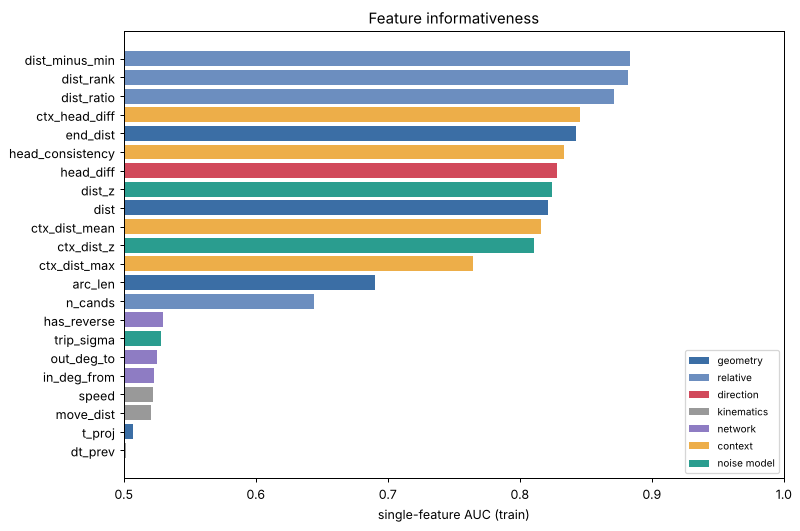

,feature,group,auc
2,dist_minus_min,relative,0.884
1,dist_rank,relative,0.882
3,dist_ratio,relative,0.871
14,ctx_head_diff,context,0.845
10,end_dist,geometry,0.842
21,head_consistency,context,0.833
5,head_diff,direction,0.828
19,dist_z,noise model,0.824
0,dist,geometry,0.822
12,ctx_dist_mean,context,0.816


In [ ]:
bad_trips = set(dp_summary[dp_summary.unreliable_labels].trip)
pts_tr = points["train"].set_index(["trip", "pt"]).label_dist_m
trn = feat["train"][~feat["train"].trip.isin(bad_trips)]
trn = trn[pts_tr.loc[list(zip(trn.trip, trn.pt))].values <= 100]
groups = {"dist": "geometry", "arc_len": "geometry", "t_proj": "geometry", "end_dist": "geometry",
          "dist_rank": "relative", "dist_minus_min": "relative", "dist_ratio": "relative", "n_cands": "relative",
          "head_diff": "direction", "speed": "kinematics", "move_dist": "kinematics", "dt_prev": "kinematics",
          "has_reverse": "network", "out_deg_to": "network", "in_deg_from": "network",
          "ctx_dist_mean": "context", "ctx_dist_max": "context", "ctx_head_diff": "context", "head_consistency": "context",
          "trip_sigma": "noise model", "dist_z": "noise model", "ctx_dist_z": "noise model"}
auc = pd.DataFrame([(f_, groups[f_], max(a, 1 - a)) for f_ in FEATURES for a in [roc_auc_score(trn.y, trn[f_])]],
                   columns=["feature", "group", "auc"]).sort_values("auc", ascending=False)
colors = {"geometry": "#3b6ea5", "relative": "#6c8ebf", "direction": "#d1495b", "kinematics": "#999999",
          "network": "#8e7cc3", "context": "#edae49", "noise model": "#2a9d8f"}
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(auc.feature, auc.auc, color=[colors[g] for g in auc.group]); ax.invert_yaxis()
for g, col in colors.items():
    ax.barh([0], [0], color=col, label=g)
ax.set(xlim=(0.5, 1), xlabel="single-feature AUC (train)", title="Feature informativeness"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
auc.round(3)

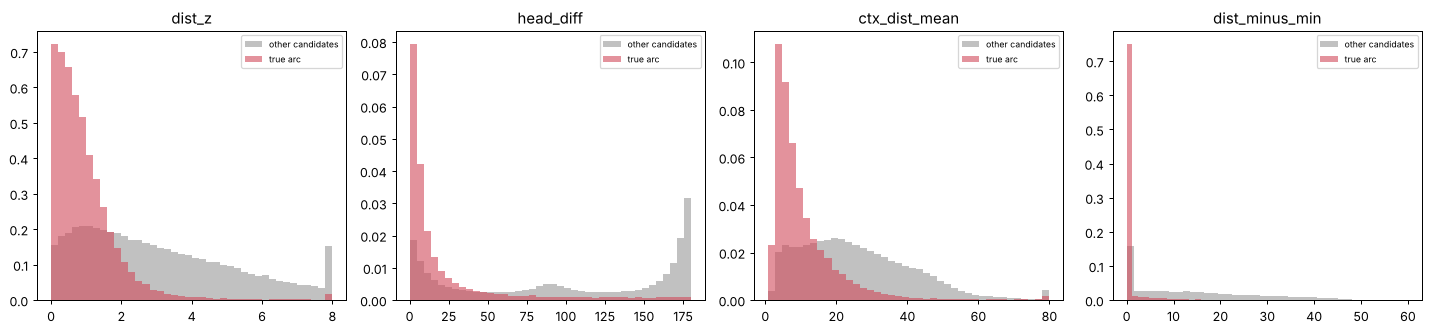

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
s = trn.sample(min(200000, len(trn)), random_state=111)
for a, f_, lim in zip(ax, ["dist_z", "head_diff", "ctx_dist_mean", "dist_minus_min"], [8, 180, 80, 60]):
    a.hist(s.loc[s.y == 0, f_].clip(upper=lim), bins=40, alpha=.6, density=True, color="#999999", label="other candidates")
    a.hist(s.loc[s.y == 1, f_].clip(upper=lim), bins=40, alpha=.6, density=True, color="#d1495b", label="true arc")
    a.set(title=f_); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

Correlated features (e.g. `dist` / `dist_z` / `dist_rank`) are kept on purpose: tree models handle redundancy,
and each adds a different view (absolute, noise-relative, relative to other candidates).

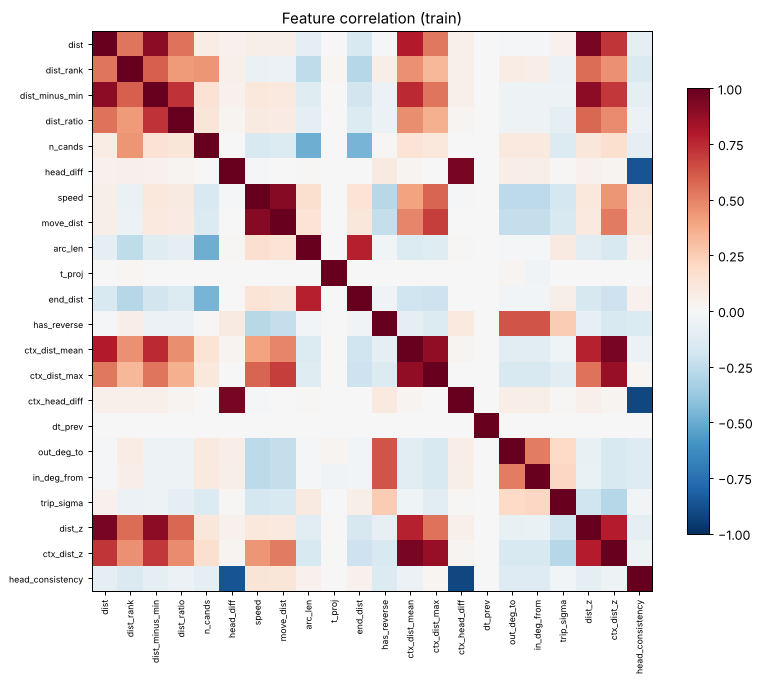

In [ ]:
corr = trn[FEATURES].sample(100000, random_state=111).corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES, fontsize=7)
plt.colorbar(im, shrink=.7); ax.set_title("Feature correlation (train)"); plt.tight_layout(); plt.show()

## Step 10 — Preparation for modelling
1. **Exclude unreliable labels:** trips flagged in notebook 01 (33, 54) and any point > 100 m from its label.
2. **Drop points whose true arc is not a candidate** (no positive to learn from) — training only; evaluation keeps them.
3. **Subsample every 3rd observation:** neighbouring 1-Hz points are near-duplicates.
4. **Group-aware folds:** GroupKFold (5 folds, groups = trip) — a trip never sits in two folds.
5. **No scaling here:** scalers (for LogReg/KNN/MLP) are fitted **inside each training fold** in a pipeline,
   so no information leaks from validation trips. Tree models need no scaling.
6. **student_test** is kept complete for development-stage evaluation only.

In [ ]:
tr = feat["train"]
tr = tr[~tr.trip.isin(bad_trips)]
tr = tr[pts_tr.loc[list(zip(tr.trip, tr.pt))].values <= 100]
tr = tr[tr.groupby(["trip", "pt"]).y.transform("max") == 1]
tr_model = tr[tr.pt % 3 == 0].reset_index(drop=True)
folds = np.full(len(tr_model), -1)
for k, (_, b) in enumerate(GroupKFold(n_splits=5).split(tr_model, groups=tr_model.trip)):
    folds[b] = k
tr_model["fold"] = folds
assert tr_model.groupby("trip").fold.nunique().max() == 1
te_model = feat["student_test"].reset_index(drop=True)
print(f"training rows: {len(feat['train']):,} -> {len(tr_model):,} after filtering + subsampling "
      f"({tr_model.trip.nunique()} trips, positive rate {tr_model.y.mean():.3f})")
print(f"student_test rows: {len(te_model):,} ({te_model.trip.nunique()} trips)")
tr_model.groupby("fold").agg(trips=("trip", "nunique"), rows=("y", "size"), positive_rate=("y", "mean")).round(3)

training rows: 1,139,914 -> 341,192 after filtering + subsampling (78 trips, positive rate 0.177)
student_test rows: 113,694 (10 trips)


,trips,rows,positive_rate
fold,,,
0,15,68479,0.183
1,15,67633,0.165
2,16,68289,0.199
3,16,68397,0.175
4,16,68394,0.162


In [ ]:
tr_model.to_pickle(os.path.join(OUT, "train_features.pkl"))
# all training rows (every observation, every trip) - needed for HMM sequences in notebook 05
full_tr = feat["train"].merge(points["train"][["trip", "pt", "label_dist_m"]], on=["trip", "pt"])
full_tr["unreliable_trip"] = full_tr.trip.isin(bad_trips)
full_tr.to_pickle(os.path.join(OUT, "train_features_all.pkl"))
te_model.to_pickle(os.path.join(OUT, "student_test_features.pkl"))
pd.DataFrame({"feature": FEATURES, "group": [groups[f_] for f_ in FEATURES]}).to_csv(os.path.join(RES, "fe_feature_list.csv"), index=False)
auc.to_csv(os.path.join(RES, "fe_feature_auc.csv"), index=False)
tr_model[["trip", "fold"]].drop_duplicates().to_csv(os.path.join(RES, "fe_cv_folds.csv"), index=False)
print("saved:", os.listdir(OUT), "+ results/fe_*.csv")

saved: ['train_features.pkl', 'student_test_features.pkl', 'train_features_all.pkl'] + results/fe_*.csv


## Step 11 — Consistency check with the production code
The API computes features with `src/pathsnap/features.py`. If the repository code is available, we check that
it gives the same values as this notebook (in Colab without the repo this check is skipped).

In [ ]:
try:
    sys.path.insert(0, os.path.join(os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else "."), "src"))
    from pathsnap.data import load_trip
    from pathsnap.features import build_features
    prod = build_features(load_trip(os.path.join(RAW, "student_test", "00000076")))
    m = demo.merge(prod, on=["pt", "arc"], suffixes=("_nb", "_prod"))
    diffs = pd.DataFrame([(f_, float(np.abs(m[f_ + "_nb"] - m[f_ + "_prod"]).max()),
                           int((np.abs(m[f_ + "_nb"] - m[f_ + "_prod"]) > 1e-6).sum())) for f_ in FEATURES],
                         columns=["feature", "max_abs_difference", "rows_different"])
    tie = m[m.dist_rank_nb != m.dist_rank_prod]
    same_dist = (tie.groupby("pt").dist_nb.transform(lambda d: d.round(6).duplicated(keep=False))).mean()
    print(f"matched {len(m):,} of {len(demo):,} rows (the rest differ only in which of two equally distant arcs is the 8th candidate)")
    print(f"features identical: {(diffs.max_abs_difference < 1e-6).sum()} of {len(FEATURES)}")
    print(f"dist_rank differs in {len(tie):,} rows; {100 * same_dist:.0f}% of them are exact distance ties "
          "(two directions of one road) numbered in a different order -> no information difference")
    display_diffs = diffs[diffs.max_abs_difference > 1e-6]
    print(display_diffs.to_string(index=False))
except ImportError:
    print("src/pathsnap not available here -> check skipped")

matched 11,036 of 11,130 rows (the rest differ only in which of two equally distant arcs is the 8th candidate)
features identical: 21 of 22
dist_rank differs in 4,405 rows; 99% of them are exact distance ties (two directions of one road) numbered in a different order -> no information difference
  feature  max_abs_difference  rows_different
dist_rank                 3.0            4405


## Summary
- **22 features in 7 groups** extracted from GPS + road network only (no route information) → usable at inference.
- Evidence: relative-distance and context features are the most informative on their own; the windowed heading
  removes most wrong-direction headings above walking speed; the noise model adapts distances per trip.
- **Prepared for modelling:** unreliable labels removed, 1-in-3 subsampling, 5 trip-grouped folds, student_test kept whole.
- Saved: `data/processed/fe/train_features.pkl`, `student_test_features.pkl`, `results/fe_*.csv`.